## Etude de la démocratisation de l’enseignement supérieur depuis l’ouverture de Parcoursup en 2018  
  
Projet Python pour la data science, ENSAE (2A), 2026-2027.  
  
La démocratisation est le processus qui permet à tous les membres d'une société d'avoir accès aux mêmes ressources, aux mêmes activités. Nous voulons donc étudier la sélection des néo bacheliers par les établissements d'enseignement supérieur : cette sélection recoupe-t-elle des critères sociaux prédéterminés, ou bien devient-elle plus démocratique, c'est-à-dire devient-elle accessible à plus de profils sociaux différents (origine géographique, boursiers, sexe ...) ? A travers cette étude se pose donc la question de la méritocratie : l'enseignement supérieur, dont la sélection est théoriquement fondée sur le mérite de chaque élève, n'est-il en vérité qu'une fabrique d'élite, un outil de reproduction sociale ?  
Nous avons souhaité concentré nos questionnements sur la période de la création de la plateforme parcoursup. Plusieurs raisons à cela : la première est purement pratique. En effet, les jeux de données de parcoursup à disposition sont relativement uniformes au cours des huit années étudiées. La seconde est théorique : nous souhaitions observer le changement depuis la création de la plateforme.  
Nous nous poserons donc la question suivante :  
  
### **Observe-t-on une démocratisation de l'enseignement supérieur depuis l'ouverture de la plateforme Parcoursup ?**  
  
Nous ne cherchons pas à établir un effet causal de la plateforme. Nous voulons simplement décrire comment le profil des candidats et des admis a évolué entre 2018 et 2025 (boursiers, type de bac, mention, origine géographique, sexe), selon la filière et la sélectivité des formations, en prenant en compte les limites de nos données.  
  
  
Plan du rapport :
1. **Les données** : Parcoursup 2018-2025, enrichi par l'IPS des lycées et par le taux de poursuite des néo-bacheliers (2010-2025).
2. **Qui accède au supérieur ?** On part de la vue d'ensemble (le taux de poursuite selon la voie du bac), puis on regarde où vont les bacheliers professionnels et technologiques.
3. **Qui est admis dans les formations sélectives ?** On y compare la place des boursiers, des différentes mentions au bac, puis des filles selon les années dans les candidature et les admissions.
4. **D'où viennent les admis ?** Nous analysons l'origine géographique comme indicateur de la mobilité des néo-bacheliers.

## 1. Les données

### Chargement et préparation de la base de données tirées de Parcoursup lors des sessions de 2018 à 2025

In [1]:
import sys
sys.path.append("..")  # pour importer le dossier sources/, situé à la racine du dépôt (chemin relatif : marche sur toutes les machines)

In [2]:
# Chargement des 8 sessions : téléchargées une seule fois, puis relues depuis data/raw/
import pandas as pd

from sources.chargement_data import charger_parcoursup, charger_poursuite, charger_ips, DATASETS
from sources.cleaning_data import preparer_base, harmoniser_ips, preparer_poursuite, base_selective
from sources.jointures import joindre_ips, panel_academies
from sources.indicateurs import (taux_poursuite, boursiers_admis_et_candidats,
                                 part_bac_admis,part_filles_globale, parts_mentions)
from sources.graphiques import courbes
from sources.carte import creer_carte


dfs = {annee: charger_parcoursup(annee) for annee in DATASETS}

Préparation de la base : identifiant de formation suivi dans le temps (`code`), sélectivité (`selective`) et filière (`filiere`) harmonisées, puis empilement des sessions. Les choix sont justifiés dans `notebooks/exploration.ipynb`.

In [3]:

base = preparer_base(dfs)

print(base.shape)
print("sélectivité manquante :", base["selective"].isna().sum())
base.groupby("session").size()

(104274, 133)
sélectivité manquante : 634


session
2018    10697
2019    11577
2020    12760
2021    13396
2022    13644
2023    13869
2024    14079
2025    14252
dtype: int64

### Enrichissement 1 : l'indice de position sociale (IPS) des lycées

L'IPS, publié par l'Éducation nationale, résume le milieu social des élèves d'un lycée : plus il est élevé, plus le milieu est favorisé. Beaucoup de CPGE et de BTS sont installés dans des lycées. On peut donc rattacher à chaque formation l'IPS du lycée qui l'accueille, grâce au code UAI et à l'année. Les trois fichiers publiés (2016-2021, 2022, 2023-2025) n'ont pas les mêmes formats : on les harmonise avant la jointure.

In [4]:
ips = harmoniser_ips(charger_ips())
base = joindre_ips(base, ips)

# Part des formations qui trouvent l'IPS de leur lycée, par filière (en %)
avec_ips = base["ips_lycee"].notna()
(avec_ips.groupby(base["filiere"]).mean() * 100).round(1).sort_values(ascending=False)

filiere
CPGE                   94.4
BTS                    85.5
Autre                  56.1
Ecole d'ingénieur       4.6
Sanitaire et social     1.0
IUT                     0.1
Ecole de commerce       0.0
LAS                     0.0
Licence                 0.0
Santé                   0.0
Name: ips_lycee, dtype: float64

Cette jointure permet de rattacher un IPS aux établissements accueillant à la fois des lycéens et des CPGE ou BTS. Cependant durant nos analyses nous avons remarqué que l'IPS décrit les élèves du lycée, pas ceux des CPGE ou des BTS qu'il accueille, donc on ne peut pas l'utiliser pour mesurer l'évolution du profil social des admis. 

### Enrichissement 2 : le taux de poursuite des néo-bacheliers dans le supérieur (2010-2025)

Ce fichier du ministère donne, pour chaque académie où le bac a été obtenu, chaque année et chaque voie du bac, le nombre de bacheliers et le nombre de ceux qui poursuivent dans le supérieur. Il commence en 2010 : on peut comparer la période APB (jusqu'en 2017) à la période Parcoursup (depuis 2018).

In [20]:
poursuite = preparer_poursuite(charger_poursuite())
poursuite

,annee,academie,voie,genre,bacheliers,poursuivants,poursuivants_meme_academie,poursuivants_autre_academie_meme_region,poursuivants_autre_region
0,2010,Aix-Marseille,Bac technologique,Féminin,3012,2161.35660,1839.30815,36.39535,285.65310
1,2011,Aix-Marseille,Bac général,Féminin,7046,6396.05350,4731.30795,111.58125,1553.16430
2,2011,Aix-Marseille,Bac professionnel,Féminin,2483,794.93440,694.55420,11.29845,89.08175
3,2011,Aix-Marseille,Bac technologique,Féminin,2968,2186.13065,1849.91650,43.12975,293.08440
4,2012,Aix-Marseille,Bac professionnel,Féminin,3649,1345.88760,1202.75880,20.73650,122.39230
...,...,...,...,...,...,...,...,...,...
2869,2025,Rennes,Bac professionnel,Féminin,4301,2021.73233,1688.80009,0.00000,332.93224
2870,2025,Rennes,Bac professionnel,Masculin,5863,2743.71439,2409.45679,0.00000,334.25760
2871,2025,Strasbourg,Bac général,Féminin,5452,5109.96697,4203.47968,121.08489,785.40240
2872,2025,Toulouse,Bac général,Féminin,8761,8255.56394,6328.45352,320.66809,1606.44233


On relie ensuite ce fichier aux admis de Parcoursup, par académie et par année. On obtient un tableau avec une ligne par académie et par année : c'est la jointure entre les deux sources. Attention : Parcoursup donne l'académie de la formation, et le fichier de poursuite l'académie du bac.

## 2. Qui accède au supérieur ?

On commence par la vue d'ensemble : quelle part des bacheliers poursuit dans le supérieur, selon la voie du bac, avant et après l'arrivée de Parcoursup.

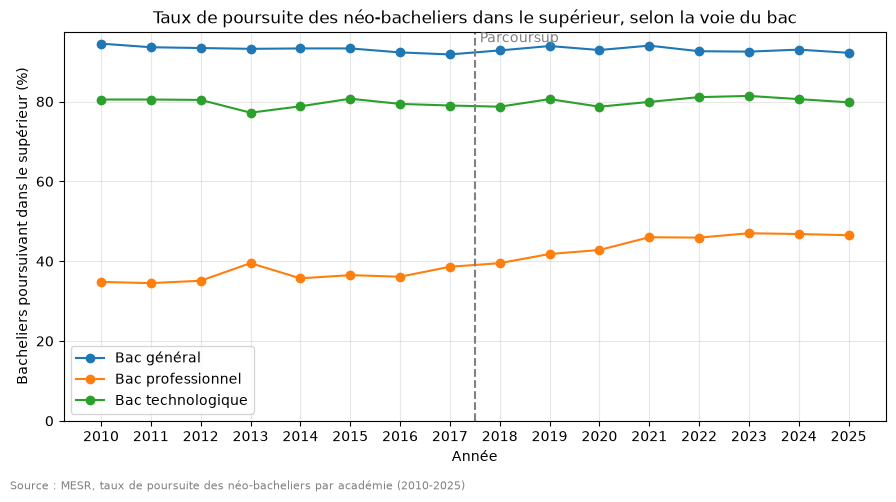

In [7]:
# Taux de poursuite (en %) par année et par voie du bac : une colonne par voie
tableau_poursuite = taux_poursuite(poursuite, ["annee", "voie"]).unstack()

courbes(tableau_poursuite,
        titre="Taux de poursuite des néo-bacheliers dans le supérieur, selon la voie du bac",
        axe_y="Bacheliers poursuivant dans le supérieur (%)",
        source="MESR, taux de poursuite des néo-bacheliers par académie (2010-2025)",
        annee_reperee=2018, texte_repere="Parcoursup");

Le taux de poursuite des bacheliers professionnels passe de 34,8 % en 2010 à 38,6 % en 2017, puis à 46,5 % en 2025. Celui des bacheliers généraux (environ 93 %) et technologiques (environ 80 %) reste stable. C'est donc chez les bacheliers professionnels que l'accès au supérieur progresse : on regarde ensuite dans quelles formations ils sont admis.

### Bacheliers professionnels et technologiques en BTS et en IUT

Deux règles visent à ouvrir les filières courtes : des places réservées aux bacheliers professionnels en BTS, et, depuis la création du BUT en 2021, un objectif d'environ la moitié de bacheliers technologiques en IUT. On suit la part de ces bacheliers parmi les néo-bacheliers admis.

,Bacs professionnels admis en BTS,Bacs technologiques admis en IUT
session,,
2018,41.2,33.8
2019,40.2,34.2
2020,40.0,34.5
2021,43.1,42.4
2022,43.7,44.0
2023,42.3,43.4
2024,43.0,45.2
2025,44.7,45.5


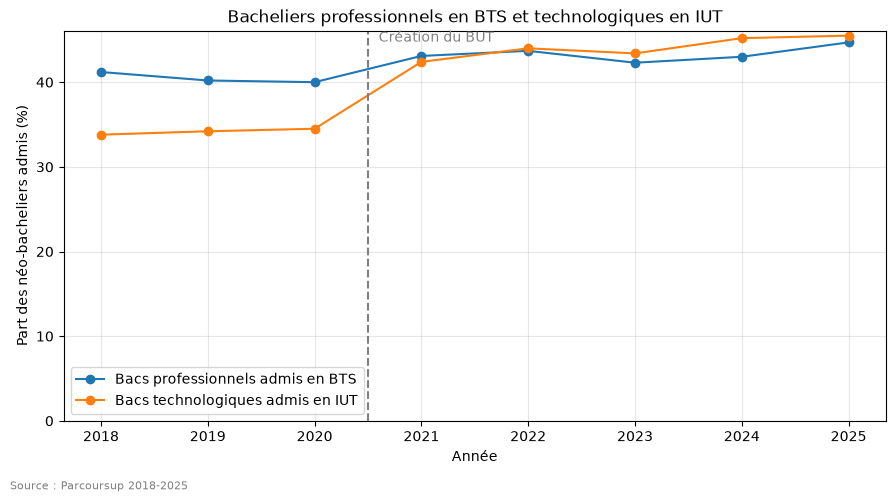

In [8]:
# Deux séries : les bacs pro admis en BTS, les bacs techno admis en IUT (en % des néo-bacheliers admis)
bacs = pd.DataFrame({
    "Bacs professionnels admis en BTS": part_bac_admis(base, "BTS", "acc_bp"),
    "Bacs technologiques admis en IUT": part_bac_admis(base, "IUT", "acc_bt"),
})

courbes(bacs,
        titre="Bacheliers professionnels en BTS et technologiques en IUT",
        axe_y="Part des néo-bacheliers admis (%)",
        source="Parcoursup 2018-2025",
        annee_reperee=2021, texte_repere="Création du BUT");
bacs

La part de bacheliers technologiques parmi les admis en IUT fait un saut en 2021, de 34,5 % à 42,4 %, l'année de la création du BUT, puis atteint 45,5 % en 2025. En BTS, la part de bacheliers professionnels progresse plus lentement, de 41,2 % en 2018 à 44,7 % en 2025. On constate donc bien une augmentation de l'admission des deux filières entre 2018 et 2025, dont on note bien que la réforme de cette filière concorde avec une meilleur entrée pour les bacheliers technologiques.  
De manière générale, ce graphique montre un accès à des filières selectives croissant au fur et à mesure des années pour les bacheliers technologiques et professionnels.

## 3. Qui est admis dans les formations sélectives ?

### La place des boursiers

La sélection est l'étape où Parcoursup peut favoriser ou freiner la démocratisation : ce sont les formations sélectives qui choisissent leurs admis. On les compare aux formations non sélectives (surtout les licences), qui accueillent une grande partie des boursiers et des bacheliers professionnels.

Les formations sélectives représentent 79 % des formations de la base.

In [9]:
formations_selectives = base_selective(base)

print(len(formations_selectives), "formations sélectives sur", len(base))

81919 formations sélectives sur 104274


Pour mesurer la place des boursiers, on ne compare pas la part de boursiers d'une année à l'autre : le nombre de boursiers recensés fait un saut en 2020 et chute en 2025, aussi bien parmi les vœux que parmi les admis. Ces sauts peuvent en effet venir des critères d'attribution de bourses qui changent selon les années et non de la sélection.

On compare donc, la même année, la part de boursiers parmi les vœux des néo-bacheliers et parmi les néo-bacheliers admis. Le rapport des deux vaut 1 si les boursiers sont aussi présents parmi les admis que parmi les vœux ; au-dessus de 1, ils sont plus présents parmi les admis.

selective,Formations non sélectives,Formations sélectives
session,,
2018,1.16,1.18
2019,1.15,1.04
2020,1.23,1.04
2021,1.22,1.07
2022,1.19,1.06
2023,1.18,1.10
2024,1.18,1.11
2025,1.15,1.06


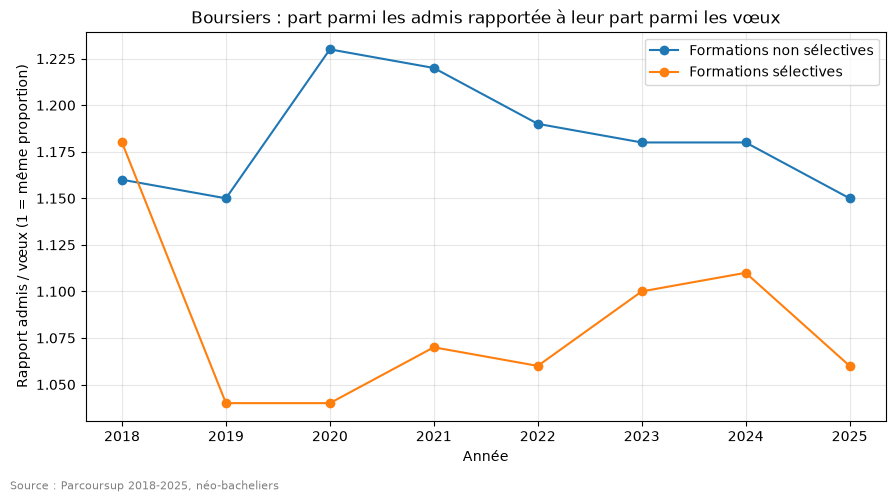

In [10]:
boursiers = boursiers_admis_et_candidats(base, ["session", "selective"])

# Rapport admis / vœux : une colonne pour les non sélectives (0) et une pour les sélectives (1)
rapport_boursiers = boursiers["rapport"].unstack().rename(columns={0.0: "Formations non sélectives",
                                                                   1.0: "Formations sélectives"})

courbes(rapport_boursiers,
        titre="Boursiers : part parmi les admis rapportée à leur part parmi les vœux",
        axe_y="Rapport admis / vœux (1 = même proportion)",
        source="Parcoursup 2018-2025, néo-bacheliers",
        depuis_zero=False);
rapport_boursiers

Chaque année, le rapport est supérieur à 1 : les boursiers sont un peu plus présents parmi les admis que parmi les vœux. L'écart est plus faible dans les formations sélectives (entre 1,04 et 1,11 depuis 2019) que dans les non sélectives (entre 1,15 et 1,23). Il ne s'élargit pas depuis 2019. En 2018, la sélectivité est reportée depuis 2020 : la valeur de cette année est à lire avec prudence.

Limites : ce sont des vœux et non des candidats (un candidat fait plusieurs vœux), et un rapport supérieur à 1 peut aussi venir des choix des candidats (vœux plus nombreux chez les non-boursiers, par exemple). On regarde ensuite le détail par filière parmi les formations sélectives.

In [11]:
# Même rapport parmi les formations sélectives, pour les principales filières
principales = formations_selectives[formations_selectives["filiere"].isin(["CPGE", "BTS", "IUT"])]
boursiers_admis_et_candidats(principales, ["session", "filiere"])["rapport"].unstack()

filiere,BTS,CPGE,IUT
session,,,
2018,1.00,1.13,0.99
2019,1.00,1.21,1.05
2020,1.00,1.10,1.05
2021,1.01,1.13,1.09
2022,0.99,1.14,1.08
2023,1.01,1.14,1.07
2024,1.00,1.11,1.05
2025,0.97,1.12,0.99


En BTS, le rapport reste proche de 1 chaque année : les boursiers sont admis dans la même proportion que leur part dans les vœux. En CPGE, il est plus élevé (entre 1,10 et 1,21) : parmi les néo-bacheliers admis en CPGE, les boursiers sont un peu plus présents que parmi les vœux. Ce sont des descriptions : elles ne disent pas si cet écart vient de la sélection des formations (par exemple des quotas de boursiers) ou des choix des candidats.

### Les mentions au bac des admis

Après le milieu social, nous nous intéressons au profil scolaire des admis : à la répartition des mention au bac dans l'enseignement supérieur. 

La limite de ce critère est que les formations selectives doivent par définition sélectionner leurs élèves sur des critères scolaires. Ainsi il paraitrait cohérent que les élèves ayant des mentions plus faibles soient désaventagés dans l'accès à certaines formations de haut niveau.

*champ : nous avons remarqué qu'il y avait un écart négatif entre la somme des mentions et le total des admis. Ainsi nous savons que les élèves ne sont comptés qu'une fois dans le total des mentions. Cependant les colonnes de mentions ne concernent en général que les néo-bacheliers (bac de l'année), alors que acc_tot inclut aussi les anciens bacheliers, les candidats en réorientation, les bacs étrangers, etc. Ces admis n'ont pas de mention dans ces colonnes. C'est pour cela que l'écart est négatif. 
Nous allons donc faire le ratio des mentions une à une sur la somme total des élèves neo-bacheliers.*

In [12]:
mentions = ["acc_sansmention", "acc_ab", "acc_b", "acc_tb", "acc_tbf", "acc_mention_nonrenseignee"]
parts = parts_mentions(base, mentions, "acc_neobac")
parts

acc_sansmention    acc_ab     acc_b    acc_tb   acc_tbf  \
selective session                                                            
0.0       2018            0.481180  0.275031  0.156715  0.079615  0.000000   
          2019            0.492091  0.269536  0.151631  0.072459  0.000000   
          2020            0.360410  0.321061  0.206948  0.104599  0.000000   
          2021            0.297689  0.366353  0.239995  0.081075  0.008221   
          2022            0.338392  0.338744  0.229898  0.083829  0.008151   
          2023            0.351169  0.331575  0.223441  0.083225  0.008745   
          2024            0.328215  0.339306  0.237141  0.086611  0.007641   
          2025            0.320625  0.340840  0.241147  0.087195  0.008841   
1.0       2018            0.328651  0.316869  0.208660  0.136827  0.000000   
          2019            0.343879  0.316947  0.207821  0.121973  0.000000   
          2020            0.209160  0.334006  0.274865  0.179188  0.000000   
          2021            0.214373  0.363863  0.274611  0.124325  0.019645   
          2022            0.254451  0.329512  0.258867  0.134580  0.021320   
          2023            0.280070  0.316064  0.246606  0.133907  0.021489   
          2024            0.277785  0.324519  0.251847  0.126221  0.018624   
          2025            0.280031  0.328525  0.247066  0.123479  0.019640   

                   acc_mention_nonrenseignee  
selective session                             
0.0       2018                      0.007458  
          2019                      0.014283  
          2020                      0.006982  
          2021                      0.006667  
          2022                      0.000035  
          2023                      0.001845  
          2024                      0.001085  
          2025                      0.001352  
1.0       2018                      0.008994  
          2019                      0.009380  
          2020                      0.002777  
          2021                      0.003183  
          2022                      0.000260  
          2023                      0.001863  
          2024                      0.001003  
          2025                      0.001259

Nous avons juste montré le phénomène global de variation du nombre d'attribution de mentions aux différentes sessions du bac.  
On va donc utiliser les chiffres sur le nombre de chaque mention au bac parmis les présents aux sessions et le nombre d'admis à chaque sessions. Ces chiffres sont présents sur les notes d'informations publiées chaque années par la DEPP suite au bac.   
Avec ces chiffres montrant l'inflation de mention au cours du temps, nous allons pourvoir corriger ce biais inflationiste dans nos chiffres sur le supérieur.

**Part des élèves avec mentions au bac entre 2018 et 2025 (en % des admis)**

In [13]:
# ajout manuel des chiffres de 2018-2019-2020 (% des présents, source : DEPP)
# Données DEPP : répartition des présents par mention (%)
# et effectifs totaux de présents et d'admis


donnees = pd.DataFrame(
    {
    "presents": [767614, 759111, 760833, 735245,
                 733104, 743874, 753147, 744412],

    "admis": [677287, 668343, 722971, 689021,
              666840, 674941, 686952, 682001],

    "acc_sansmention": [40.6, 41.1, 32.5, 29.7,
                        32.3, 33.9, 33.0, 33.1],

    "acc_ab": [26.0, 25.8, 31.5, 34.1,
               30.3, 29.1, 30.0, 30.2],

    "acc_b": [14.1, 14.1, 20.3, 21.3,
              19.4, 18.7, 19.5, 19.6],

    # Très bien + félicitations du jury à partir de 2021
    "acc_tb": [7.5, 7.1, 10.7, 8.7,
               9.0, 9.0, 8.7, 8.8]
    },
        index=pd.Index([2018, 2019, 2020,2021,2022,2023,2024,2025], name="session")
        )


df_bacheliers = pd.DataFrame(donnees)

# Correction du biais lié aux candidats non admis
facteur = df_bacheliers["presents"] / df_bacheliers["admis"]

colonnes_mentions = [
    "acc_sansmention",
    "acc_ab",
    "acc_b",
    "acc_tb"
]

for col in colonnes_mentions:
    df_bacheliers[col] = df_bacheliers[col] * facteur

# Tableau final
#df_bacheliers = df_bacheliers[
#    ["session"] + colonnes_mentions]

df_bacheliers[colonnes_mentions] = (
    df_bacheliers[colonnes_mentions].round(2)
)

print(df_bacheliers)



         presents   admis  acc_sansmention  acc_ab  acc_b  acc_tb
session                                                          
2018       767614  677287            46.01   29.47  15.98    8.50
2019       759111  668343            46.68   29.30  16.01    8.06
2020       760833  722971            34.20   33.15  21.36   11.26
2021       735245  689021            31.69   36.39  22.73    9.28
2022       733104  666840            35.51   33.31  21.33    9.89
2023       743874  674941            37.36   32.07  20.61    9.92
2024       753147  686952            36.18   32.89  21.38    9.54
2025       744412  682001            36.13   32.96  21.39    9.61


**correction du biais inflationniste sur les mentions**  
Nous créons un indice : part de la mention dans le supérieur / part de la mention au bac (même année)

Un indice de 1 signifie que le supérieur recrute le même profil que l'ensemble des bacheliers. Au-dessus de 1, la mention est sur-représentée, et si l'indice monte, le supérieur recrute plus de bonnes mentions que ce que l'inflation seule explique. Et inversement, pour les indice en dessous de 1.

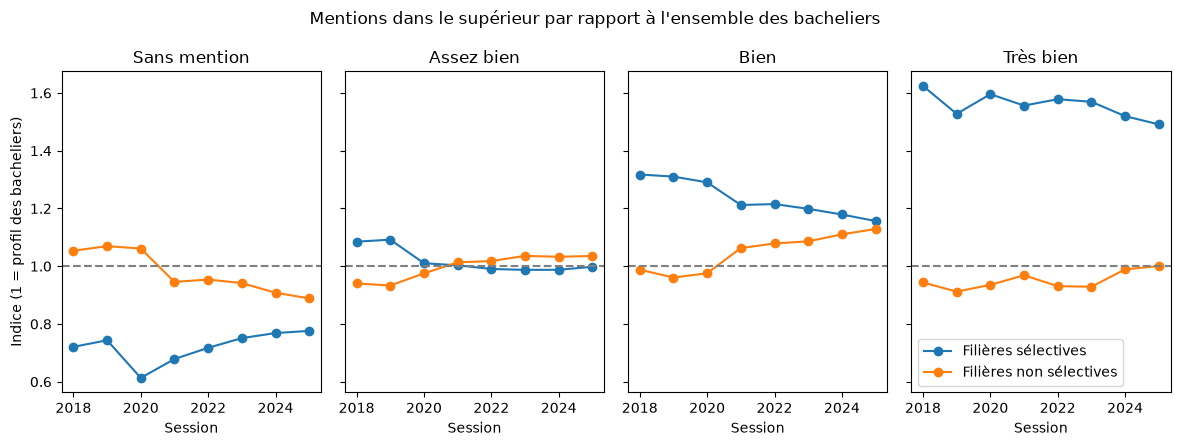

In [14]:
from sources.indicateurs import indice_mentions
from sources.graphiques import graphique_indice_mentions

indice = indice_mentions(base, df_bacheliers)
fig = graphique_indice_mentions(
    indice,
    mentions=("acc_sansmention", "acc_ab", "acc_b", "acc_tb"),
)

La correction de l'inflation des mentions au baccalauréat permet de dépasser la simple augmentation du niveau scolaire des bacheliers pour observer l'évolution réelle des profils recrutés dans l'enseignement supérieur.

Dans les filières sélectives, les bacheliers sans mention restent nettement sous-représentés : leur indice est de 0,72 en 2018, descend à 0,61 en 2020, puis remonte à 0,78 en 2025. À l'inverse, les titulaires d'une mention bien ou très bien y demeurent surreprésentés. La surreprésentation des mentions bien diminue lentement (de 1,32 en 2018 à 1,16 en 2025), tandis que celle des mentions très bien reste particulièrement élevée sur toute la période (de 1,62 en 2018 à 1,49 en 2025). Ces résultats montrent que les filières sélectives continuent de concentrer les meilleurs profils scolaires, malgré une légère atténuation des écarts.

Dans les filières non sélectives, les indices restent proches de 1 : la répartition des mentions y est proche de celle de l'ensemble des bacheliers. Les bacheliers sans mention, légèrement surreprésentés jusqu'en 2020 (indice de 1,05 à 1,07), deviennent sous-représentés à partir de 2021, avec un indice de 0,89 en 2025. Parallèlement, les mentions bien passent de 0,99 à 1,13, et les mentions très bien de 0,94 à 1,00.

Finalement, les filières sélectives continuent de privilégier les meilleurs dossiers, tandis que les filières non sélectives accueillent des profils plus proches de l'ensemble des bacheliers, mais avec une évolution défavorable aux bacheliers sans mention.

### La mixité dans les formations sélectives

Un autre critère permettant d'observer l'ouverture de l'enseignement supérieur à l'ensemble de la population est la mixité. En effet, depuis de nombreuses années, le système éducatif français cherche à rétablir la mixité dans toutes les formations (on pense en particulier aux formations sélectives scientifiques). 

Nous allons donc regarder comment ce critère a évolué depuis 2019.

Attention : on commence en 2019. En 2018, la part de filles parmi les vœux (41 % dans les formations sélectives, 46 % dans l'ensemble) est très inférieure à celle des années suivantes (55 % en 2019) : la colonne voe_tot_f ne semble pas comptée de la même façon cette année-là. Ce sont aussi des vœux et non des candidates (une candidate fait plusieurs vœux).

In [15]:
# Parts de filles (en %) parmi les vœux et parmi les admis, à partir de 2019 (2018 n'est pas comparable)
part_voeux = part_filles_globale(formations_selectives, "voe_tot_f", "voe_tot") * 100
part_admis = part_filles_globale(formations_selectives, "acc_tot_f", "acc_tot") * 100

comparaison = pd.DataFrame({
    "Part de filles parmi les vœux": part_voeux,
    "Part de filles parmi les admises et admis": part_admis,
}).loc[2019:]
comparaison["Écart (admis - vœux, en points)"] = (
    comparaison["Part de filles parmi les admises et admis"]
    - comparaison["Part de filles parmi les vœux"]
)
comparaison.round(1)

,Part de filles parmi les vœux,Part de filles parmi les admises et admis,"Écart (admis - vœux, en points)"
session,,,
2019,55.0,51.0,-4.0
2020,54.4,51.0,-3.3
2021,54.1,50.3,-3.8
2022,53.3,50.3,-2.9
2023,52.1,50.5,-1.6
2024,52.2,50.7,-1.5
2025,52.3,50.7,-1.6


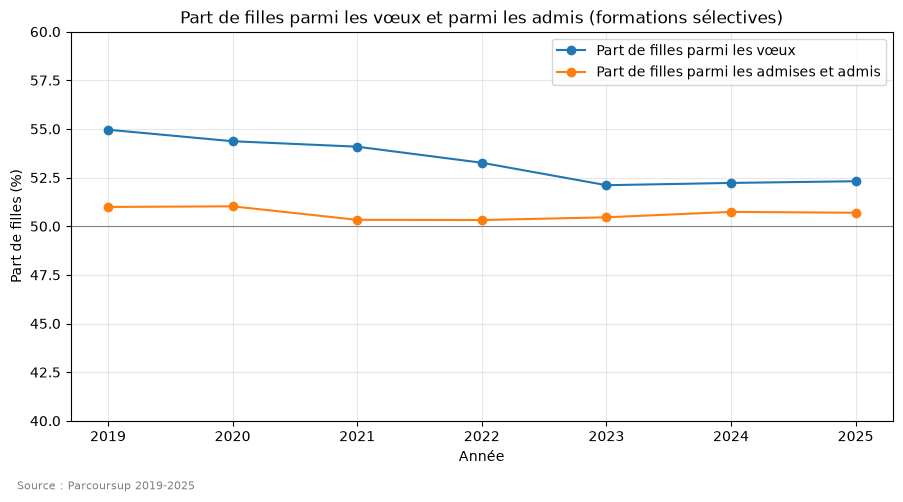

In [16]:
# Même fonction que les autres courbes du rapport, avec un axe de 40 à 60 % centré sur la parité
fig = courbes(comparaison.iloc[:, :2],
              titre="Part de filles parmi les vœux et parmi les admis (formations sélectives)",
              axe_y="Part de filles (%)",
              source="Parcoursup 2019-2025",
              depuis_zero=False)
ax = fig.axes[0]
ax.set_ylim(40, 60)
ax.axhline(50, color="grey", linewidth=0.8)   # ligne de la parité

L'analyse de la part des filles qui candidatent puis sont admises dans des formations sélectives met en évidence un décalage persistant entre les vœux et l'admission, visible par l'écart entre les deux courbes. Il existe une différence constante de 2 à 4 points entre la part de filles qui candidatent et la part de filles réellement admises. Cela indique que les filles formulent un peu plus de vœux en proportion, mais que le taux d'accès final aboutit à un équilibre proche de 50/50 dans les formations sélectives.

On remarque par ailleurs que cet écart se réduit au fil du temps, passant d'environ 4 points en 2019 à près de 2 points entre 2023 et 2025. Cette réduction de l'écart s'explique principalement par une diminution progressive de la part des vœux féminins (qui passe de 55 % à 52 %), tandis que la proportion d'admises reste stable.

Enfin, la part des filles parmi les candidats admis demeure extrêmement stable, ancrée de manière constante autour de la stricte parité (50,5 % à 51 %) sur toute la période. Cette stabilisation démontre que malgré une légère diminution de la proportion de candidates dans ces filières, l'équilibre paritaire des admis est préservé, bien qu'inférieur de quelques points à la proportion initiale de vœux.

## 4. D'où viennent les admis ?

### L'origine géographique des admis

In [17]:
agg_mobilite, fig_cartes, fig_anim = creer_carte(base)
agg_mobilite.pivot(index="academie", columns="session", values="part_entrants").round(1).style.format("{:.1f}").set_caption("Part des admis venant d'une autre académie, par académie et par session (en %)")


session,2018,2019,2020,2021,2022,2023,2024,2025
academie,,,,,,,,
Aix-Marseille,19.9,22.0,21.7,24.8,23.9,22.1,21.5,21.2
Amiens,18.3,21.6,21.3,22.8,22.6,21.3,22.9,21.3
Besançon,17.8,22.4,19.8,22.4,21.1,19.5,21.9,20.0
Bordeaux,18.7,21.1,21.2,23.5,24.5,24.1,24.6,22.1
Clermont-Ferrand,30.0,32.1,31.4,32.3,32.0,31.8,32.5,30.8
Corse,9.1,10.1,9.6,11.4,10.8,8.4,12.8,13.1
Créteil,29.6,33.6,34.5,37.8,40.6,38.8,39.5,40.7
Dijon,21.1,22.9,22.4,24.4,26.0,24.0,26.5,25.8
Etranger,29.9,46.7,75.7,80.7,77.9,73.8,71.0,63.0


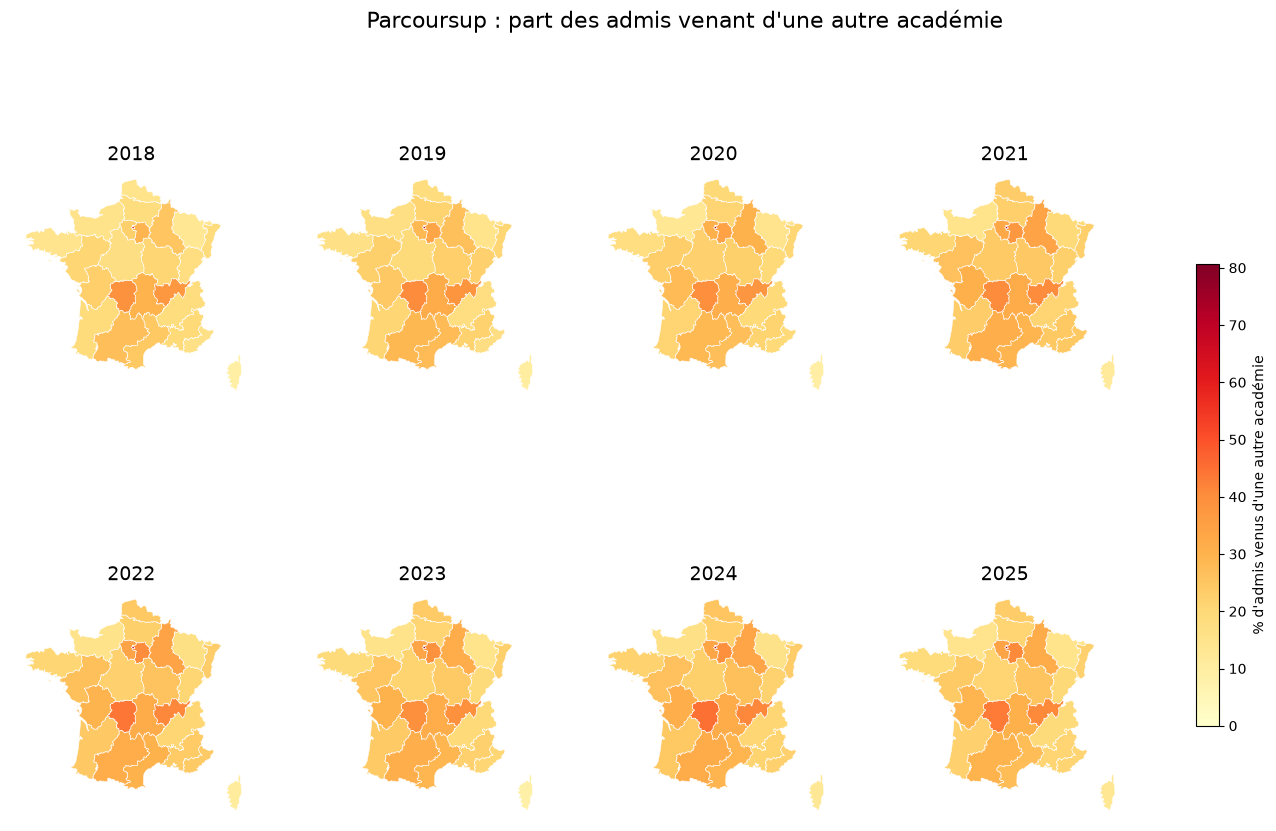

In [18]:
fig_cartes          # carte statique

In [19]:
fig_anim.show()     # carte animée

Ici donc, nous constatons globalement une augmentation assez homogène sur toute la France du nombre d’admis de chaque filière venant d’une autre académie entre 2018 et 2015. Les résultats sont des moyennes par académie, et nous pouvons constater par exemple que l’académie de Paris augmente son nombre d’admis venant d’autres académies d’environ dix points de pourcentage (d’environ 67% à environ 77%). L’augmentation est sensible pour chaque académie. 
La répartition des différents taux au travers des académies semble rester identique (une zone forte au centre et au sud, une zone plus clair au nord de Paris, et une zone très forte pour Paris et l’Ile de France).

## Conclusion

Entre 2018 et 2025, en parallèle à l’ouverture de Parcoursup, nous avons constaté :   

-   Une augmentation du taux de poursuite dans le supérieur des bacheliers professionnels et tecnologiques. Cela n'est pas du qu'à Parcoursup mais aussi à l'ouverture des BUT qui permette de garantir des places dans des formations sélectives pour ces bacheliers.
-   Une différence entre la part des admis rapportée à la part parmi les vœux toujours supérieur à 1 depuis 2018, ainsi, les boursiers ne sont pas désavantagés lors des selections. Mais il est notable que les formations non selectives favorisent plus les boursiers que les formations sélectives au vu de l'écart entre les deux courbes.
-	Une part plus faible de la sélection des filles aux formations auxquelles elles ont candidaté ;   
-	Une convergence des formations sélectives et non sélectives vis-à-vis de la sélection des élèves selon leur mention. Nous avons remarqué une grande convergence pour les sans mentions, les mentions assez bien et les mentions bien, mais la convergence du côté des mentions très bien reste très faible et l’écart assez grand ;    
-	Une augmentation homogène sur le territoire de la part d’admis venant d’autres académies, donc une plus grande diversification géographique des profils ;  


Ainsi, nous constatons divers changements depuis 2018, concomitants à l’ouverture de la plateforme Parcoursup. Certains vont dans le sens d’une plus grande ouverture sociale des profils sélectionnés (plus de variété géographique), d’autres sont moins remarquables… 
 
Il est ainsi trop dur de conclure de façon univoque à la question de l’ouverture sociale de la sélection des écoles du supérieur. Des changements sont constatables, et géographique peut-être en premier lieu, mais les autres conclusions restent assez ténues.